# 19 – K-Means: Läuft eine Station im Optimum oder schlechter?

**Zweck:** Folie 5 des Projektpartners teilt die Stationen in drei Klassen mit je
einer Handlungsempfehlung:

| Klasse | Empfehlung |
|---|---|
| Station läuft gut | **kein Handlungsbedarf** |
| Station läuft schlechter als möglich, Technik in Ordnung | **Regelparameter optimieren** |
| Regelventil schließt nicht | **Regelventil tauschen** |

Das Ventil erkennen die Modelle in Notebook 20 und 22. Für die übrigen Stationen
bleibt die Frage: **Optimum oder schlechter?** Dafür braucht es kein Label —
K-Means gruppiert die Stationen nach ihrem Regelverhalten, und die Gruppe mit dem
kältesten Rücklauf ist das Optimum, an dem sich die anderen messen.

### Die Vorgeschichte: viermal K-Means, viermal kein Fehlerdetektor

K-Means war im Projekt das erste Werkzeug, zu dem alle gegriffen haben, auch ich:

| Versuch | Notebook | Ergebnis |
|---|---|---|
| Stationscluster aus 14 Kennzahlen | [`01`](01_kmeans_stationscluster.ipynb) (Seb) | keine natürlichen Gruppen, Silhouette unter 0,25 |
| Betriebszustände auf Stundenwerten | [`04`](04_kmeans_operatingConditions.ipynb) (Pauline) | typische Betriebspunkte, aber kein Bezug zu Fehlern |
| Tagestypen je Temperaturgruppe | [`06`](06_tagesmerkmale_clusteranalyse.ipynb) (Seb) | Tagestypen erkennbar; der schlechteste Typ hängt mit schlechter Abkühlung zusammen |
| Stationsprofile und Zentrumsabstand als Anomalie-Score | [`02`](02_gesamtpipeline_rohdaten_bis_wartungsbenchmark.ipynb) (meine, August) | zwei Profile (54 und 24 HAST); der Abstand zum Zentrum trennt Stationen mit und ohne Maßnahme **nicht** (AUC 0,51) |

**Was daraus folgt:** K-Means findet Gruppen, aber „weit weg vom Zentrum“ heißt nicht
„defekt“. Hier wird K-Means deshalb anders eingesetzt: nicht als Fehlerdetektor,
sondern für **genau eine** Frage der Folie 5, Optimum oder schlechter. Dafür bekommt es
nur die drei Größen, die das Regelverhalten beschreiben. Ob die Gruppen scharf getrennt
sind, ist zweitrangig. Entscheidend ist, ob sie sich an den Begehungen bewähren
(Abschnitt 6 und 7).

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | die drei Regelungs-Kennzahlen je Zähler (Winter 23/24), Labels, Stundenwerte |

**Ergebnis:** `data/processed/kmeans_einstufung.csv` — Gruppe und Einstufung je Zähler, gebraucht in Notebook 22.

## 1 · Setup & Daten laden

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
print(f"Kennzahlen: {kz.shape[0]} Zähler × {kz.shape[1]} Spalten")
print(f"Labels:     {labels.shape[0]} begangene Zähler × {labels.shape[1]} Spalten")
kz.head()

Kennzahlen: 96 Zähler × 16 Spalten
Labels:     56 begangene Zähler × 11 Spalten


,stunden_winter,stunden_sommer,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag
zaehler,,,,,,,,,,,,,,,,
41704231,4391.0,2206.0,0.0,0.000000,NaN,34.414197,NaN,40.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41704232,4391.0,2206.0,0.0,0.000000,NaN,35.769853,NaN,42.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
53198226,3467.0,2206.0,10.0,0.657609,14.2,44.779441,32.069805,54.5,0.647601,0.339623,0.102304,0.962280,0.830796,42.945283,1.31201,NaN
58177363,4389.0,0.0,NaN,NaN,NaN,42.136805,32.330807,47.6,0.622559,0.622807,NaN,0.844506,0.596419,39.223518,NaN,NaN
58177384,923.0,0.0,NaN,NaN,NaN,57.144011,25.307972,57.5,0.467353,0.580292,NaN,1.167188,0.588327,51.064065,NaN,NaN


In [2]:
labels.head()

,begehungen,erste_begehung,strasse_gruppe,vertrag_alt_kw,vertrag_neu_kw,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert
zaehler,,,,,,,,,,,
65273846,1,NaT,8,8.0,8.0,False,True,False,False,False,0.0
68956339,1,2024-11-25,3,NaN,NaN,False,False,True,True,True,NaN
68956342,2,2024-09-18,7,NaN,NaN,False,True,True,False,True,NaN
68956344,1,2024-09-20,7,8.0,8.0,False,False,False,False,True,0.0
68956345,1,2024-09-18,13,14.0,14.0,False,False,True,False,True,0.0


**Was man sieht**
- `kz` hat eine Zeile je Zähler (96) mit den Kennzahlen aus Notebook 18. Einige Felder sind leer,
  wo im Winter oder Sommer zu wenig gemessen wurde.
- `labels` hat eine Zeile je begangenem Zähler (56) mit Datum, Straßennummer, Vertragswerten und den
  sechs Labels. Nicht begangene Zähler stehen dort gar nicht.

In [3]:
MERKMALE = ["anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet"]
daten = kz[MERKMALE].dropna()
print(f"{len(daten)} von {len(kz)} Zählern haben alle drei Kennzahlen")
daten.describe().round(2)

89 von 96 Zählern haben alle drei Kennzahlen


,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
count,89.00,89.00,89.00
mean,0.81,0.72,46.56
std,0.37,0.17,8.88
min,-0.10,0.19,30.72
25%,0.72,0.62,41.27
50%,0.91,0.71,45.40
75%,1.04,0.83,51.18
max,1.44,1.16,69.18


**Was macht diese Zelle?**
- Lädt die Kennzahlen und Labels aus Notebook 18.
- Nimmt die drei Größen, die beschreiben, **wie** eine Station regelt. Alle drei stammen
  aus dem Winter 23/24, also vor den Begehungen:

| Kennzahl | hoch heißt | niedrig heißt |
|---|---|---|
| `anteil_volumenstrom` | der Durchfluss folgt der Last (gut) | der Durchfluss läuft konstant weiter, das Ventil drosselt nicht |
| `streubreite_betriebspunkte` | Betriebspunkte springen | gleichbleibender Betrieb |
| `ruecklauf_lastgewichtet` | Wasser kommt heiß zurück (schlecht) | gute Auskühlung |

- Zähler mit weniger als 200 Laststunden im Winter haben keine Werte und werden nicht eingestuft.

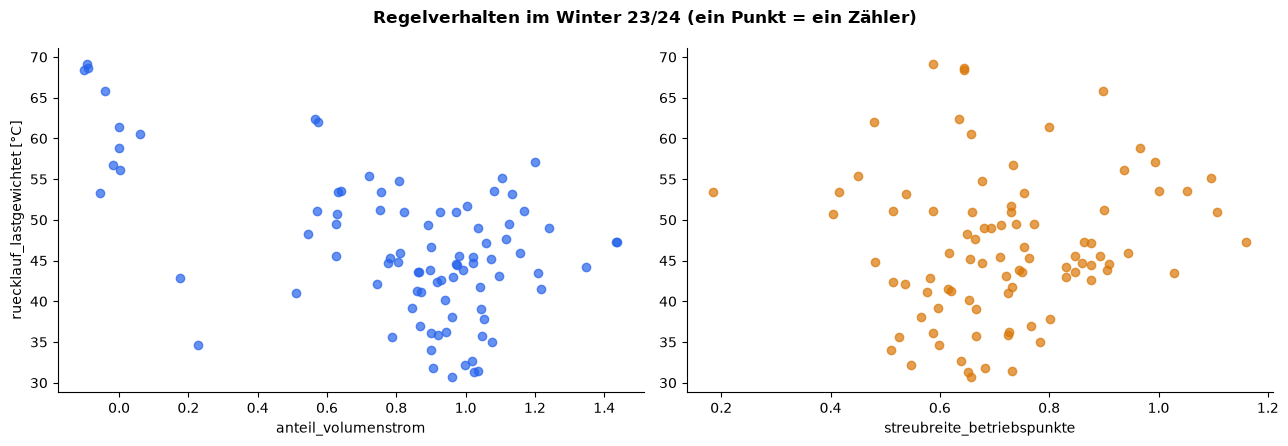

Korrelationen:


,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
anteil_volumenstrom,1.00,0.17,-0.55
streubreite_betriebspunkte,0.17,1.00,0.10
ruecklauf_lastgewichtet,-0.55,0.10,1.00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(daten["anteil_volumenstrom"], daten["ruecklauf_lastgewichtet"], color="#2563EB", alpha=0.7)
axes[0].set_xlabel("anteil_volumenstrom")
axes[0].set_ylabel("ruecklauf_lastgewichtet [°C]")
axes[1].scatter(daten["streubreite_betriebspunkte"], daten["ruecklauf_lastgewichtet"], color="#D97706", alpha=0.7)
axes[1].set_xlabel("streubreite_betriebspunkte")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Regelverhalten im Winter 23/24 (ein Punkt = ein Zähler)", fontweight="bold")
fig.tight_layout()
plt.show()
print("Korrelationen:")
daten.corr().round(2)

**Was macht diese Zelle?**
- Zeigt die Rohdaten, bevor K-Means sie sieht: links Durchflussanteil gegen Rücklauf,
  rechts Streubreite gegen Rücklauf.

**Was man sieht**

- Links oben sitzt eine eigene Wolke: Stationen mit `anteil_volumenstrom` um 0 und einem Rücklauf zwischen 55 und 70 °C. Dort läuft der Durchfluss konstant weiter, egal wie viel Wärme gebraucht wird. Das Wasser kommt deshalb heiß zurück.
- Die Korrelation bestätigt das: Durchflussanteil und Rücklauf hängen mit −0,55 zusammen. Die Streubreite hängt mit keinem der beiden stark zusammen (0,17 und 0,10).

## 2 · Vorverarbeitung

K-Means misst euklidische Abstände. Ohne Skalierung würde der Rücklauf (Spanne
rund 30 K) die beiden anderen Größen (Spanne rund 1) völlig überdecken. Deshalb
bekommt jede Kennzahl Mittelwert 0 und Standardabweichung 1.

In [5]:
skalierer = StandardScaler()
X = skalierer.fit_transform(daten)
pd.DataFrame(X, columns=MERKMALE, index=daten.index).describe().round(2).loc[["mean", "std", "min", "max"]]

,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
mean,-0.00,-0.00,-0.00
std,1.01,1.01,1.01
min,-2.47,-3.16,-1.79
max,1.71,2.61,2.56


**Was macht diese Zelle?**
- `StandardScaler` zieht je Spalte den Mittelwert ab und teilt durch die Standardabweichung.
- Die Tabelle zeigt zur Kontrolle: Mittelwert 0, Streuung 1 in allen drei Spalten.

## 3 · Wie viele Gruppen? Elbow und Silhouette

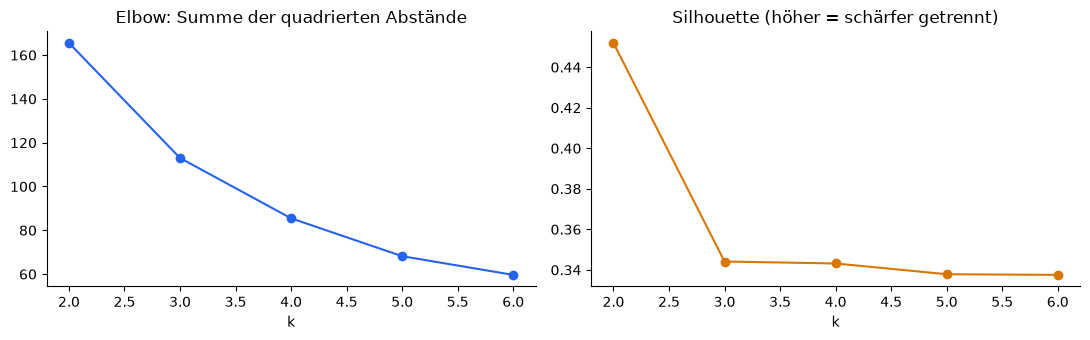

Beste Silhouette bei k = 2: 0.452


,inertia,silhouette
k,,
2,165.551,0.452
3,113.005,0.344
4,85.468,0.343
5,68.172,0.338
6,59.632,0.338


In [6]:
suche = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=25, random_state=0).fit(X)
    suche.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
suche = pd.DataFrame(suche).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(suche.index, suche["inertia"], "o-", color="#2563EB")
axes[0].set_title("Elbow: Summe der quadrierten Abstände")
axes[1].plot(suche.index, suche["silhouette"], "o-", color="#D97706")
axes[1].set_title("Silhouette (höher = schärfer getrennt)")
for ax in axes:
    ax.set_xlabel("k")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

K = int(suche["silhouette"].idxmax())
print(f"Beste Silhouette bei k = {K}: {suche.loc[K, 'silhouette']:.3f}")
suche.round(3)

**Was macht diese Zelle?**
- Rechnet K-Means für k = 2 bis 6, jeweils mit 25 Startpunkten (`n_init`), und behält je k
  die beste Lösung.
- **Elbow:** Wo die Kurve abknickt, bringt eine weitere Gruppe wenig.
- **Silhouette:** misst je Station, ob sie ihrer eigenen Gruppe näher ist als der
  nächsten. 1 wäre perfekt, 0 heißt: liegt genau dazwischen.
- Gewählt wird das k mit der besten Silhouette.

**Ergebnis**

- **k = 2 ist klar am besten:** Silhouette 0,45. Ab k = 3 fällt sie auf rund 0,34 und bleibt dort. Die Elbow-Kurve hat keinen scharfen Knick; sie bestätigt also nichts, widerspricht aber auch nicht.
- Das passt zur Frage dieses Notebooks: zwei Gruppen, Optimum und schlechter.
- Zum Vergleich: [`01_kmeans`](01_kmeans_stationscluster.ipynb) kam mit allen Kennzahlen auf eine Silhouette unter 0,25. Mit den drei Regelungsgrößen sind die Gruppen deutlich schärfer getrennt.

## 4 · K-Means fitten und die Gruppen benennen

In [7]:
km = KMeans(n_clusters=K, n_init=25, random_state=0).fit(X)
daten["cluster"] = km.labels_

# Die Gruppe mit dem kältesten Rücklauf ist das Optimum; die anderen werden danach sortiert.
reihenfolge = daten.groupby("cluster")["ruecklauf_lastgewichtet"].mean().sort_values().index
namen = {c: chr(ord("A") + i) for i, c in enumerate(reihenfolge)}
daten["gruppe"] = daten["cluster"].map(namen)
daten["einstufung"] = np.where(daten["gruppe"] == "A", "Optimum", "schlechter")

zentren = pd.DataFrame(skalierer.inverse_transform(km.cluster_centers_), columns=MERKMALE)
zentren["gruppe"] = [namen[c] for c in range(K)]
profil = zentren.set_index("gruppe").sort_index()
profil["Zähler"] = daten["gruppe"].value_counts().sort_index()
profil.round(2)

,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,Zähler
gruppe,,,,
A,0.96,0.74,43.57,71
B,0.24,0.63,58.34,18


**Was macht diese Zelle?**
- Fittet K-Means mit dem gewählten k.
- Benennt die Gruppen nach ihrem Rücklauf: **A** ist die mit dem kältesten Rücklauf, also
  das **Optimum**. Alle anderen Gruppen gelten als „schlechter“.
- Die Tabelle zeigt die Gruppenmitten zurückgerechnet in die echten Einheiten, damit man
  sie lesen kann.

**Die zwei Gruppen**

| Gruppe | Zähler | Durchflussanteil | Rücklauf | Bedeutung |
|---|---|---|---|---|
| **A — Optimum** | 71 | 0,96 | 43,6 °C | der Durchfluss folgt der Last, das Wasser wird gut ausgekühlt |
| **B — schlechter** | 18 | 0,24 | 58,3 °C | der Durchfluss läuft fast konstant, der Rücklauf ist rund 15 K heißer |

- Getrennt wird vor allem über Durchflussanteil und Rücklauf. Die Streubreite unterscheidet sich kaum (0,74 gegen 0,63).
- Gruppe B ist genau das Bild aus Folie 5: Die Station regelt nicht über den Durchfluss, das Regelventil drosselt nicht oder ist falsch eingestellt.

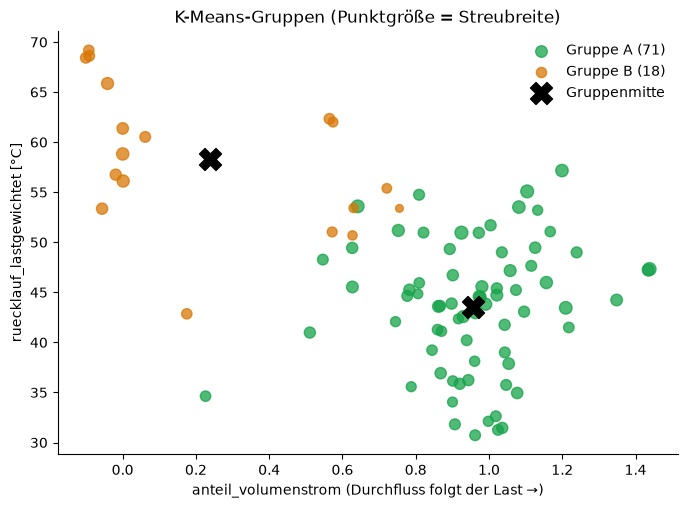

In [8]:
farben = {chr(ord("A") + i): f for i, f in enumerate(["#16A34A", "#D97706", "#DC2626", "#7C3AED", "#0891B2", "#64748B"])}
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, g in daten.groupby("gruppe"):
    ax.scatter(g["anteil_volumenstrom"], g["ruecklauf_lastgewichtet"], s=20 + 60 * g["streubreite_betriebspunkte"],
               color=farben[name], alpha=0.75, label=f"Gruppe {name} ({len(g)})")
ax.scatter(profil["anteil_volumenstrom"], profil["ruecklauf_lastgewichtet"], marker="X", s=250, color="black", label="Gruppenmitte")
ax.set_xlabel("anteil_volumenstrom (Durchfluss folgt der Last →)")
ax.set_ylabel("ruecklauf_lastgewichtet [°C]")
ax.set_title("K-Means-Gruppen (Punktgröße = Streubreite)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Zeigt die Gruppen in den zwei anschaulichsten Achsen. Die dritte Größe, die Streubreite,
  steckt in der Punktgröße.

## 5 · Wie stabil sind die Gruppen?

Zwei Fragen:

1. **Hängt das Ergebnis am Zufallsstart?** K-Means beginnt mit zufälligen
   Startpunkten. Mit 25 Starts je Lauf sollte bei jedem Seed dieselbe Einteilung
   herauskommen.
2. **Hängt es an einzelnen Stationen?** Wichtiger: Wäre die Einteilung mit etwas
   anderen Daten noch dieselbe? Dafür wird 200-mal eine Bootstrap-Stichprobe
   gezogen (Stationen mit Zurücklegen), K-Means darauf neu gefittet und dann für
   **alle** Stationen die Gruppe bestimmt.

Gemessen wird mit dem **Adjusted Rand Index** (1 = identische Einteilung, 0 = nicht
besser als Zufall) und mit dem Anteil der Stationen, deren Einstufung gleich bleibt.

In [9]:
seeds = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=25, random_state=s).fit(X).labels_)
         for s in range(20)]
print(f"1) 20 Seeds: ARI Minimum {np.min(seeds):.2f} (1 = immer dieselbe Einteilung)")

rng = np.random.default_rng(0)
optimum = daten["einstufung"].eq("Optimum").to_numpy()
ari, gleich = [], []
for _ in range(200):
    stichprobe = rng.integers(0, len(X), len(X))
    km_b = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X[stichprobe])
    neu = km_b.predict(X)
    ari.append(adjusted_rand_score(km.labels_, neu))
    # Optimum der Bootstrap-Lösung = Gruppe mit dem kältesten Rücklauf
    opt_b = np.argmin(skalierer.inverse_transform(km_b.cluster_centers_)[:, MERKMALE.index("ruecklauf_lastgewichtet")])
    gleich.append(np.mean((neu == opt_b) == optimum))
print(f"2) 200 Bootstrap-Stichproben: ARI Median {np.median(ari):.2f}, 5-%-Quantil {np.quantile(ari, 0.05):.2f}")
print(f"   gleiche Einstufung Optimum/schlechter: im Median {np.median(gleich):.0%} der Stationen, "
      f"im schlechtesten Zwanzigstel {np.quantile(gleich, 0.05):.0%}")

1) 20 Seeds: ARI Minimum 0.95 (1 = immer dieselbe Einteilung)


2) 200 Bootstrap-Stichproben: ARI Median 0.90, 5-%-Quantil 0.21
   gleiche Einstufung Optimum/schlechter: im Median 98% der Stationen, im schlechtesten Zwanzigstel 76%


**Was macht diese Zelle?**
- Teil 1 fittet K-Means mit 20 verschiedenen Seeds und vergleicht jede Einteilung mit der von oben.
- Teil 2 zieht 200-mal eine Stichprobe der Stationen mit Zurücklegen (manche doppelt,
  manche gar nicht), fittet K-Means darauf und ordnet dann alle Stationen der nächsten
  Gruppenmitte zu. Die Optimum-Gruppe wird dabei jedes Mal neu über den kältesten
  Rücklauf bestimmt.

**Ergebnis**

- **Der Zufallsstart spielt keine Rolle:** Über 20 Seeds bleibt die Einteilung praktisch gleich (ARI ≥ 0,95).
- **Gegen andere Daten ist sie meist stabil:** Im Median behalten 98 % der Stationen ihre Einstufung, wenn K-Means auf einer Bootstrap-Stichprobe neu gefittet wird.
- **Aber nicht immer:** In den ungünstigsten 5 % der Stichproben sind es nur 76 %. Das betrifft die Grenzfälle: die Punkte mit Durchflussanteil um 0,6–0,75, die im Bild nah an Gruppe A liegen. Für sie ist die Einstufung unsicher; für die Wolke links oben nicht.

## 6 · Gegenprobe: Passen die Gruppen zu den Begehungen?

K-Means kennt die Befunde nicht. Wenn die Einstufung etwas taugt, sollten Stationen
der „schlechteren“ Gruppen bei der Begehung häufiger einen Befund gehabt haben.
Geprüft wird je Fehlerart mit dem exakten Test nach Fisher, weil die Zahlen klein sind.

In [10]:
LABELS = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
begangen = daten.join(labels[LABELS], how="inner")
print(f"{len(begangen)} begangene Zähler sind eingestuft "
      f"({(begangen['einstufung'] == 'Optimum').sum()} Optimum, {(begangen['einstufung'] == 'schlechter').sum()} schlechter)")

zeilen = []
for label in LABELS:
    b = begangen.dropna(subset=[label])
    tafel = pd.crosstab(b["einstufung"] == "schlechter", b[label].astype(bool)).reindex(index=[False, True], columns=[False, True], fill_value=0)
    _, p = fisher_exact(tafel)
    zeilen.append({
        "Fehlerart": label,
        "Optimum: Befund": f"{tafel.loc[False, True]} von {tafel.loc[False].sum()}",
        "schlechter: Befund": f"{tafel.loc[True, True]} von {tafel.loc[True].sum()}",
        "Anteil Optimum": tafel.loc[False, True] / max(tafel.loc[False].sum(), 1),
        "Anteil schlechter": tafel.loc[True, True] / max(tafel.loc[True].sum(), 1),
        "p (Fisher)": p,
    })
gegenprobe = pd.DataFrame(zeilen).set_index("Fehlerart")
gegenprobe.round(3)

54 begangene Zähler sind eingestuft (45 Optimum, 9 schlechter)


,Optimum: Befund,schlechter: Befund,Anteil Optimum,Anteil schlechter,p (Fisher)
Fehlerart,,,,,
ventil,6 von 45,5 von 9,0.133,0.556,0.012
daemmung,19 von 45,3 von 9,0.422,0.333,0.723
filter,19 von 45,6 von 9,0.422,0.667,0.275
durchfluss,16 von 45,3 von 9,0.356,0.333,1.000
temperatur,28 von 45,6 von 9,0.622,0.667,1.000
ueberdimensioniert,8 von 31,1 von 4,0.258,0.250,1.000


**Was macht diese Zelle?**
- Nimmt nur die begangenen Zähler, die eingestuft sind.
- Stellt je Fehlerart eine Vierfeldertafel auf (Optimum/schlechter × Befund ja/nein) und
  rechnet den Fisher-Test. p < 0,05 heißt: Ein so großer Unterschied wäre bei reinem Zufall selten.
- Sechs Tests auf einmal: Bei einem einzelnen p knapp unter 0,05 ist Vorsicht angebracht.

**Ergebnis**

- **Ventil:** In Gruppe B hatten 5 von 9 begangenen Stationen einen Ventilbefund, im Optimum 6 von 45 (56 % gegen 13 %, p = 0,012). K-Means kennt die Befunde nicht und findet trotzdem die Stationen, an denen das Ventil getauscht wurde. Bei sechs Tests ist das allerdings knapp: Nach der strengen Holm-Korrektur läge p bei 0,07.
- **Alle anderen Fehlerarten:** Kein Unterschied (p ≥ 0,27). Dämmung, Filter, Durchfluss, Temperatur und Vertragsleistung kommen im Optimum genauso oft vor wie in Gruppe B.
- **Was das für Folie 5 heißt:** „Schlechter“ ist zur Hälfte das Ventilbild. Deshalb muss die Reihenfolge stimmen: zuerst das Ventil erkennen (Notebook 20 und 22), dann die übrigen Stationen der Gruppe B als „Regelparameter optimieren“ einstufen.

## 7 · Zweite Gegenprobe: Wo hat die Begehung etwas gebracht?

Wenn „schlechter“ wirklich heißt „da ist Luft nach oben“, dann sollte eine Begehung
bei diesen Stationen den Rücklauf stärker senken als beim Optimum. Verglichen wird
der lastgewichtete Rücklauf im Winter 23/24 (vorher) mit dem im Winter 24/25
(nachher), getrennt nach Einstufung und danach, ob bis Ende 2024 begangen wurde.
Die nicht begangenen Stationen zeigen, wie sich der Rücklauf **ohne** Begehung
verändert hat (anderes Wetter, Netz).

In [11]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet",
                          columns=["zaehler", "timestamp", "ruecklauf", "durchfluss", "spreizung", "leistung"])
w2425 = stunden[(stunden["timestamp"] >= "2024-10-01") & (stunden["timestamp"] < "2025-04-01")]
last = w2425[(w2425["leistung"] > 0.5) & (w2425["durchfluss"] > 1) & (w2425["spreizung"] > 1)].dropna(subset=["ruecklauf"])
rl_2425 = last.groupby("zaehler").apply(
    lambda g: np.average(g["ruecklauf"], weights=g["leistung"]) if len(g) >= 200 else np.nan)

wirkung = daten[["einstufung", "ruecklauf_lastgewichtet"]].rename(columns={"ruecklauf_lastgewichtet": "rl_2324"})
wirkung["rl_2425"] = rl_2425
wirkung["aenderung_k"] = wirkung["rl_2425"] - wirkung["rl_2324"]
datum = labels["erste_begehung"].reindex(wirkung.index)
wirkung["begangen"] = np.select([datum <= "2024-12-31", datum.notna()], ["bis Ende 2024", "erst 2025"], "nie")
wirkung = wirkung[wirkung["begangen"] != "erst 2025"].dropna(subset=["aenderung_k"])

tabelle = wirkung.groupby(["begangen", "einstufung"])["aenderung_k"].agg(["size", "mean", "median"]).round(2)
tabelle.columns = ["Zähler", "Änderung Mittel [K]", "Änderung Median [K]"]
tabelle

Zähler  Änderung Mittel [K]  Änderung Median [K]
begangen      einstufung                                                  
bis Ende 2024 Optimum         34                -0.07                -0.66
              schlechter       7                -6.40                -3.06
nie           Optimum         27                -0.15                 0.04
              schlechter       8                -4.68                -1.83

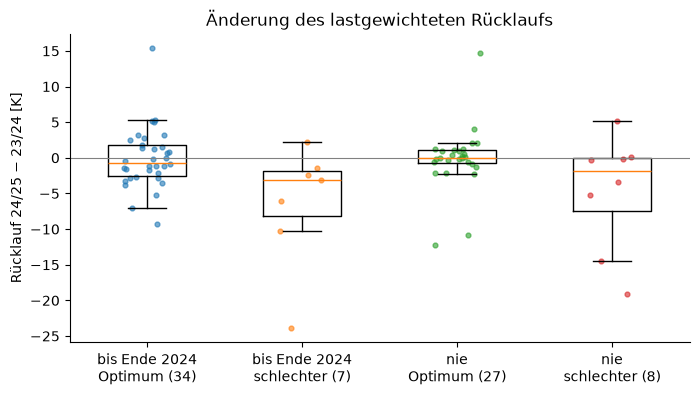

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
positionen, beschriftung = [], []
for i, (schluessel, g) in enumerate(wirkung.groupby(["begangen", "einstufung"])):
    ax.boxplot(g["aenderung_k"], positions=[i], widths=0.5, showfliers=False)
    ax.scatter(np.full(len(g), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(g)), g["aenderung_k"], s=12, alpha=0.6)
    positionen.append(i)
    beschriftung.append(f"{schluessel[0]}\n{schluessel[1]} ({len(g)})")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(positionen, beschriftung)
ax.set_ylabel("Rücklauf 24/25 − 23/24 [K]")
ax.set_title("Änderung des lastgewichteten Rücklaufs")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was machen die beiden Zellen?**
- Rechnet den lastgewichteten Rücklauf für den Winter 24/25 genau wie in Notebook 18.
- Zieht den Wert aus dem Winter 23/24 ab: negativ heißt, der Rücklauf ist gesunken (gut).
- Stationen, die erst 2025 begangen wurden, fallen heraus, weil der Winter 24/25 bei
  ihnen noch vor der Begehung lag.

**Ergebnis**

- **Optimum:** Der Rücklauf ändert sich kaum, ob begangen oder nicht (Median −0,7 und 0,0 K).
- **Gruppe B:** Der Rücklauf sinkt deutlich, bei begangenen Stationen im Mittel um 6,4 K (Median −3,1 K, 7 Zähler).
- **Aber er sinkt auch ohne Begehung:** bei den nie begangenen Stationen der Gruppe B um 4,7 K (Median −1,8 K, 8 Zähler). Das ist **Regression zur Mitte**: Wer im Winter 23/24 extrem schlecht lag, liegt im nächsten Winter oft weniger extrem, auch ohne Eingriff.
- Der Unterschied zwischen begangen und nicht begangen beträgt in Gruppe B nur 1–2 K, bei 7 gegen 8 Stationen. Das lässt sich nicht belastbar trennen.
- **Einordnung:** Die Einstufung zeigt, **wo Luft nach oben ist**: In Gruppe A bewegt sich fast nichts, in Gruppe B viel. Dass die Begehung die Ursache der Verbesserung war, lässt sich hier nicht nachweisen.

## 8 · Ergebnis speichern

In [13]:
daten[MERKMALE + ["gruppe", "einstufung"]].to_csv(PROCESSED / "kmeans_einstufung.csv")
print(daten["einstufung"].value_counts().to_string())

einstufung
Optimum       71
schlechter    18


**Was macht diese Zelle?**
- Schreibt Gruppe und Einstufung je Zähler. Notebook 22 kombiniert das mit der
  Ventil-Erkennung zu den drei Klassen der Folie 5.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

Eine Einstufung aller 89 Zähler mit genug Wintermessungen in **Optimum (71)** und **schlechter (18)**, nur aus dem Regelverhalten im Winter 23/24 und ohne ein einziges Label. Gespeichert in `kmeans_einstufung.csv`.

| Prüfung | Ergebnis | Bewertung |
|---|---|---|
| Trennschärfe | Silhouette 0,45 bei k = 2 (Notebook 01: unter 0,25) | **deutlich besser als alle Kennzahlen zusammen** |
| Stabilität | Median 98 % gleiche Einstufung im Bootstrap, schlechtestes Zwanzigstel 76 % | **stabil, bis auf Grenzfälle** |
| Gegenprobe Ventil | 56 % gegen 13 % Ventilbefunde, p = 0,012 | **bestanden**, nach Holm-Korrektur knapp (0,07) |
| Gegenprobe übrige Fehlerarten | kein Unterschied | **nicht bestanden** |
| Wirkung der Begehung | Gruppe B verbessert sich stark, aber auch ohne Begehung | **nicht nachweisbar** (Regression zur Mitte) |

### Wie das Ergebnis einzuordnen ist

- K-Means trennt die Stationen sauber in **gut regelnde** und **konstant durchströmte**. Das ist genau die Unterscheidung „Optimum gegen schlechter“ aus Folie 5.
- Gruppe B ist etwa zur Hälfte das Ventilbild. Für die drei Klassen der Folie heißt das: **erst das Ventil**, dann der Rest. Diese Reihenfolge setzt Notebook 22 um.
- Über Dämmung, Filter oder Durchfluss sagt die Einstufung nichts. Diese Fehler verändern das Regelverhalten offenbar nicht so, dass es in diesen drei Größen sichtbar wird.
- **Schwach:** Nur 9 begangene Stationen liegen in Gruppe B. Jede Aussage über diese Gruppe ruht auf wenigen Fällen.